<a href="https://colab.research.google.com/github/akshin-kuvshin/numerical-methods/blob/main/lab5/lab5.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Лабораторная работа №5. Интерполирование по равноотстоящим узлам

## Выполнил: Данила Аксёнов, гр. 932420

## Вариант: 1

In [107]:
import numpy as np
from matplotlib import pyplot as plt
print('Setup completed')

Setup completed


### Исходные данные:

In [108]:
n = 11
x = np.linspace(1, 2, num=n)
h = 0.1 # шаг таблицы
y = np.array([0.322, 0.284, 0.241, 0.193, 0.135, 0.063, -0.031, -0.164, -0.369, -0.741, -1.664])
eps = 0.0005 # общая абсолютная погрешность

In [109]:
def plot_nodes(color='black', label=None):
    plt.plot(x, y, marker='x', linestyle='None', color=color, label=label)

In [110]:
# точки, значения функции в которых необходимо аппроксимировать
x1_star = 0.98
x2_star = 1.56

## **Задание 10**

* Построить таблицу конечных разностей для функции, заданной в виде таблицы $ (x_i, y_i) $ на равномерной сетке;
* Считая, что табличные значения заданы с верными знаками, определить наивысший порядок правильных конечных разностей;
* Выбрать интерполяционные формулы и с помощью этих формул найти приближенное значение интерполируемой функции в точках $ x_1^* $ и $ x_2^* $. Обосновать выбор интерполяционных формул;
* При построении интерполяционной формулы использовать только правильные конечные разности, но не выше четвёртого порядка.

### Решение:

In [111]:
d = [y] # таблица конечных разностей
for i in range(1, n):
    d_i = np.zeros(n - i)
    for j in range(0, n - i):
        d_i[j] = d[i - 1][j + 1] - d[i - 1][j]
    d.append(d_i)
d

[array([ 0.322,  0.284,  0.241,  0.193,  0.135,  0.063, -0.031, -0.164,
        -0.369, -0.741, -1.664]),
 array([-0.038, -0.043, -0.048, -0.058, -0.072, -0.094, -0.133, -0.205,
        -0.372, -0.923]),
 array([-0.005, -0.005, -0.01 , -0.014, -0.022, -0.039, -0.072, -0.167,
        -0.551]),
 array([-5.55111512e-17, -5.00000000e-03, -4.00000000e-03, -8.00000000e-03,
        -1.70000000e-02, -3.30000000e-02, -9.50000000e-02, -3.84000000e-01]),
 array([-0.005,  0.001, -0.004, -0.009, -0.016, -0.062, -0.289]),
 array([ 0.006, -0.005, -0.005, -0.007, -0.046, -0.227]),
 array([-1.10000000e-02, -8.32667268e-17, -2.00000000e-03, -3.90000000e-02,
        -1.81000000e-01]),
 array([ 0.011, -0.002, -0.037, -0.142]),
 array([-0.013, -0.035, -0.105]),
 array([-0.022, -0.07 ]),
 array([-0.048])]

---

In [112]:
# ищем максимальный порядок правильных конечных разностей
for i in range(n - 1):
    if np.abs(d[i]).max() >= (2 ** i) * eps and np.abs(d[i + 1]).max() < (2 ** (i + 1)) * eps:
        r = i
        break
r

7

In [113]:
r = min(r, 4) # в дальнейшем будем использовать правильные конечные разности не выше четвёртого порядка
r

4

---

In [114]:
# предпосчитаем факториалы для чисел до r=4 включительно - это пригодится нам в дальнейшем
fact = np.ones(r + 1)
for i in range(1, r + 1):
    fact[i] = fact[i - 1] * i
fact

array([ 1.,  1.,  2.,  6., 24.])

---

Первая точка, значение функции в которой необходимо аппроксимировать $ - $ $ x_1^* = 0.98 $ $ - $, находится вблизи начала таблицы, т.е. вблизи точки $ x_0 = 1 $, поэтому здесь уместно применить _1-ю интерполяционную формулу Ньютона_ (для интерполирования вперёд).

In [115]:
def f_newton1(x0):
    t0 = (x0 - x[0]) / h

    y0 = y[0]
    numerator = 1
    for i in range(1, r + 1):
        numerator *= (t0 - i + 1)
        y0 += numerator / fact[i] * d[i][0]
    return y0

In [116]:
y1_star = f_newton1(x1_star)
y1_star

np.float64(0.328648)

Получили результат $ f(x_1^*) = f(0.98) \approx 0.33 $, что согласуется с имеющимися данными: на протяжение всей таблицы функция $ f $ убывает, причём скорость убывания растёт экспоненциально $ - $ примерно двукратно увеличивается с каждым новым узлом таблицы.

---

Вторая точка $ x_2^* = 1.56 $ находится в середине таблицы, причём расстояние до ближайшего узла справа $ - $ $ x_6 = 1.6 $ $ - $ немного меньше, чем аналогичное расстояние слева (до узла $ x_5 = 1.5 $), поэтому я решил использовать _2-ю формулу Гаусса_ (для интерполирования назад).

In [117]:
def f_gauss2(x0, k):
    t0 = (x0 - x[k]) / h

    y0 = y[k]
    numerator = 1
    for i in range(1, r + 1):
        numerator *= t0 + (i // 2) * (1 - 2 * (i % 2))
        y0 += numerator / fact[i] * d[i][k - (i + 1) // 2]
    return y0

In [118]:
y2_star = f_gauss2(x2_star, 6)
y2_star

np.float64(0.009969600000000037)

Получили результат $ f(x_2^*) = f(1.56) \approx 0.01 $, что также выглядит вполне правдоподобно.

---

Для удобства представления изобразим узлы таблицы и аппроксимированные значения функции в точках $ x_1^* = 0.98 $ и $ x_2^* = 1.56 $ на графике:

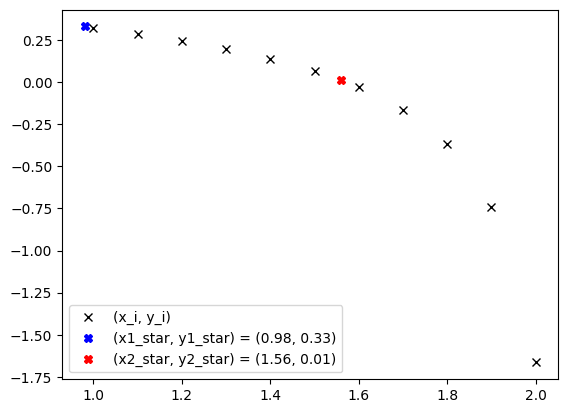

In [119]:
plot_nodes(label='(x_i, y_i)')
plt.plot(x1_star, y1_star, marker='X', linestyle='None', color='blue', label=f'(x1_star, y1_star) = ({x1_star}, {y1_star:.2f})')
plt.plot(x2_star, y2_star, marker='X', linestyle='None', color='red', label=f'(x2_star, y2_star) = ({x2_star}, {y2_star:.2f})')
plt.legend()
plt.show()